# Midterm project

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This midterm project is due on Friday, October 24, 2025, at 11:59 pm Eastern Time.**   
(Submission via the shared `GitHub` repository.)

## Rules:

* You can use all resources discussed in the lecture except other human and AI resources, including `ChatGPT`. Collaborations with other students are not allowed.
* Answer the questions in this `Jupyter` notebook and use `Python3` for your computations. Solutions in other programming languages will not be accepted.
* Feel free to ask the [lead instructor](https://github.com/ohiou-inpp-ntg/2025-phys-4071-5071#general-information) questions (see office hours).
* Comment your programs adequately so we know that you understand your code. Your functions should have at least a one-line [docstring](https://peps.python.org/pep-0257/) that explains their purpose.
* Points will be deducted for programs returning warnings and/or not running from the top to the bottom of the Jupyter Notebook. Before you submit your homework, we recommend restarting the kernel and running all cells in order, e.g., using `Kernel > Restart & Run All`.
* Label your plots adequately, e.g., so we know what is plotted and what the axes mean. Show legends with meaningful labels if more than one dataset is plotted. 
* Explain your solutions and analytic calculations clearly through coherent text and, if necessary, $\LaTeX$ expressions in `markdown` cells.
* Submit your project like any previous homework (i.e., via the shared GitHub repository) _before_ the deadline (see above). Submission must be done before the deadline to be accepted. 
* If you encounter technical issues with the submission process, try to upload your project manually as described [here](https://docs.github.com/en/repositories/working-with-files/managing-files/adding-a-file-to-a-repository). If that does not work, email your solutions to the [lead instructor](https://github.com/ohiou-inpp-ntg/2025-phys-4071-5071#general-information) _before_ the deadline and explain the technical issue.

**Good luck!**

----
## Temperature of a light bulb

An incandescent light bulb contains a filament, usually made of tungsten, heated by the flow of electricity until it becomes hot enough to radiate thermally. Essentially, all the power consumed by such a bulb is radiated as electromagnetic energy, but some of that radiation is not in the visible wavelengths, which means it is useless for lighting purposes.

Let us define the **efficiency of a light bulb** as the fraction of the radiated energy that falls in the visible band. It's a good approximation to assume that the radiation from a filament at temperature $T$ obeys the Planck radiation law, meaning that the power radiated per unit wavelength $\lambda$ obeys

$$
I(\lambda) = 2 \pi A h c^2 \frac{\lambda^{-5}}{e^{hc/(\lambda k_B T)} -1 } \,,
$$

where $A$ is the surface area of the filament, $h$ is Planck's constant, $c$ is the speed of light, and $k_B$ is Boltzmann's constant. The visible wavelengths run from $\lambda_1 = 390$ nm to $\lambda_2 = 750$ nm so the total energy radiated in the visible window is $\int_{\lambda_1}^{\lambda_2} I(\lambda) d\lambda$ whereas the total energy at all wavelengths is $\int_{0}^{\infty} I(\lambda) d\lambda$. 

Using the substitution $x = hc/(\lambda k_B T)$, we get the expression for the light bulb's efficiency:

$$ \boxed{
\eta = \frac{\int_{\lambda_1}^{\lambda_2} I(\lambda) d\lambda}{\int_{0}^{\infty} I(\lambda) d\lambda} = \frac{15}{\pi^4} \int_{hc/(\lambda_2 k_B T)}^{hc/(\lambda_1 k_B T)} \frac{x^3}{e^x-1} dx \,,
}
$$

where the leading constants and the area $A$ have canceled out.

**Constants**:

\begin{align}
h &= 6.62607015 \times 10^{-34} \, \mathrm{J} \, \mathrm{s}\\
c &= 299792458 \, \mathrm{m}/\mathrm{s}\\
k_B &= 1.380649 \times 10^{-23} \, \mathrm{J} \, \mathrm{K}^{-1}
\end{align}

1. Write a `Python` function that takes a temperature $T$ as its argument and calculates the value of $\eta$ for that temperature from the formula above. 
   - The integral in the boxed expression above cannot be evaluated analytically, but you can do it numerically using two methods of your choice: one has to be adaptive, the other one non-adaptive. 
   - Estimate the error of your numerical calculations. 
   - Use your own implementations of the integrators, not existing library implementations.

In [1]:
#Q1 Part 1.) Making function n (integration process) 
import math
import numpy as np 


# Defining constants of problem 
Pi = np.pi
h = 6.62607015e-34 # planck's constants; units: J-s
c = 299792458  # speed of light (c); units: m/s 
k_B = 1.380649e-23 # Boltzman Constant (k_B); units: J/K 
lambda_1 = 390e-9 # wavelength can be expressed in nm but in base units 10^-9 m 
lambda_2 = 750e-9 # wavelength can be expressed in nm but in base units 10^-9 m 


# 1st Function is arguemnt of integration 
eta_arg = lambda x : x**3/(np.exp(x) - 1.0) 

# derivative of functional argument (what's inside integral) 
der_eta_arg = lambda x : (3*x**2 * (np.exp(x) -1) - x**3 * np.exp(x))/(pow((np.exp(x) - 1.0), 2))


# Function that defines eta (n) using trapezoidal Rule (non-adaptive approach)
def eta_trap_rule(f, f_prime, a, b, N): 
    ''' Computes eta (n) using the Trapezoidal Rule over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. This is argument of the integrand.
    f_prime: function 
        derivative of finction given. Used for error approximation. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float or numpy array
        Approximation of the integral given by the Trapezoidal Rule. Result will be value or set of values based on if
        boundary conditions are functional.
        
    '''
    x = np.linspace(a, b, N+1) # Grid-points of integrand
    h = (b - a)/N # h-stepsizes 
    Int = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) # Trapezoidal rule calculation.
    final_eta = (15.0/Pi**4)*Int # Eta calculation.  
    eta_error = abs((15.0/Pi**4)*(1.0/12.0)*h**2 * (f_prime(a) - f_prime(b))) # Euler-Mcclaurin error approximate for eta function. 
    return final_eta, eta_error 


# Another definition of eta (n) using 6th-order Romberg (adaptive approach) 
def eta_rom(f, f_prime, a, b, N): 
    ''' This function is the adaptive approach takes trapezoidal rule form of eta and redefines it to be evaluated for 6-th order 
        Romberg value and error. 
        
    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. This is argument of the integrand.
    f_prime: function 
        derivative of function given. Used for error approximation. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float or numpy array 
        Approximation of the integral given by the adapted Trapezoidal Rule (6th-orde Romberg). Result will be value or set of values based on if
        boundary conditions are functional.
        
    '''
    # Trapezoidal rule elements that are 1st column entries in lower triangular.
    T_11, T_11_er = eta_trap_rule(f, f_prime, a, b, N) 
    T_21, T_21_er = eta_trap_rule(f, f_prime, a, b, 2*N) 
    T_31, T_31_er = eta_trap_rule(f, f_prime, a, b, 4*N) 
    T_41, T_41_er = eta_trap_rule(f, f_prime, a, b, 8*N)
    
    # Other elements that makeup lower triangular matrix.
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)
    T_42 = T_41 + (1.0/3.0)*(T_41 - T_31)
    T_43 = T_42 + (1.0/15.0)*(T_42 - T_32)
    
    # Error for 6th-order system.
    err_rhom = abs((64.0/63.0)*(T_43 - T_33))
    
    return T_33, err_rhom 

# a(T) functional form of boundary condition 
def a_T(T): 
    ''' This function essentially defines boundary "a" that will be used in trapezoidal/romberg functions that defines "a" as function of 
        T (Temperature) 
    Parameters
    ---------
    T: float or numpy array 
       Per particular temperature or vector of temperatures. 
    Returns
    -------
    float or numpy array
    The boundary condition "a" as specific value or essentially in vectorized form of T. 
    '''

    final_a_t = (h*c)/(lambda_2*k_B*T)
    return final_a_t 


# b(T) functional form of boundary condition 
def b_T(T): 
    ''' This function essentially defines boundary "b" that will be used in trapezoidal/romberg functions that defines "b" as function of 
        T (Temperature) 
    Parameters
    ---------
    T: float or numpy array 
       Per particular temperature or vector of temperatures. 
    Returns
    -------
    float or numpy array
    The boundary condition "b" as specific value or essentially in vectorized form of T. 
    '''
    final_b_t = (h*c)/(lambda_1*k_B*T)
    return final_b_t 

#Test case for trapezoidal rule and 6th-order Romberg 
T_1 = 3000.0 # Unit: K (kelvin) 
a_1 = a_T(T_1) 
b_1 = b_T(T_1) 
eta_1, eta_error_1 = eta_trap_rule(eta_arg, der_eta_arg, a_1, b_1, 1000)
eta_R, eta_err_R = eta_rom(eta_arg, der_eta_arg, a_1, b_1, 100)
print(f" (Trap Rule) For  T = {T_1} K case: eta = {eta_1:1.15e}; and eta_eror = {eta_error_1: 1.15e}") 
print(f"\n (6-th Rhomb Rule) For  T = {T_1} K case: eta = {eta_R:1.15e}; and eta_eror = {eta_err_R: 1.18e}") 





 (Trap Rule) For  T = 3000.0 K case: eta = 1.086285257817559e-01; and eta_eror =  1.013105419223307e-07

 (6-th Rhomb Rule) For  T = 3000.0 K case: eta = 1.086284244712147e-01; and eta_eror =  1.550787716936726510e-16


2. Use your function to make a graph of $\eta$ as a function of the temperature $T$ between $300$ K and $10000$ K. You should see that there is an intermediate temperature where the efficiency is maximum. 

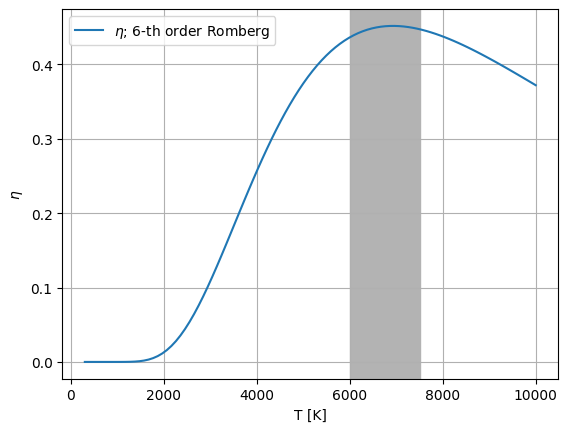

 Temperature of maximum efficiency by visual inspection: 6750.0 K.


In [2]:
#Q1 Part 2.) plotting of efficiency 

import math
import numpy as np 
import matplotlib.pyplot as plt 


# Temperature array (Unit: K) and N
N  = 100
T = np.linspace(300.0, 10000.0, N)

# Romberg Setup for plotting
eta = [] 
error = [] 
for i in T: 
    a = a_T(i) 
    b = b_T(i) 
    eta_i, err_i = eta_rom(eta_arg, der_eta_arg, a, b, N)
    eta.append(eta_i) 
    error.append(err_i) 

    
# Plotting of eta per T 
plt.plot(T, eta, label = r"$\eta$; 6-th order Romberg") 
plt.legend(loc="best") 
plt.ylabel(r"$\eta$")
plt.xlabel("T [K]")
plt.axvspan(6000, 7500, color="0.7", zorder=0)
plt.grid(True)
plt.show()


print(f" Temperature of maximum efficiency by visual inspection: {(6000.0 + 7500.0)/2.0} K.") 

3. Calculate the temperature of maximum efficiency of the light bulb to within $0.1$ K or better using the golden ratio search. Estimate the error of your result.

In [3]:
#Q1 Part 3.) Golden ratio test 
import math
import numpy as np 


def gms(T1, T4, tol):
    ''' This function uses the golden ratio test to find the temperature (K) of maximum efficiency. The key 
        detail is to pick T1 and T4 outside the maxima peak, and also to invert efficiency function to turn this into 
        finding a minimum, which is what the golden ratio does. 
    Parameters
    ---------
    T1: float 
        Outside left-bound temperature of the minima assumption.
    T4: float 
        Outside right-bound temperature of the minima assumption.
    tol: float 
        Break condition for the golden ratio algorithm.
  
    Returns
    -------
    float 
    The temperature that corresponds to maximum efficiency from the golden-ratio algorithm. The maxima is turned into minima to 
    do algorithm.
    
    '''
    golden_mean = (1.0 + np.sqrt(5.0))/2.0
    max_iter = 100 ; i_ter = 0
    while abs(T1 - T4) > tol and i_ter < max_iter:
        # defining error 
        error = abs(T1 - T4) 
        
        # print status
        if i_ter < 5 or i_ter % 5 == 0:
            print(f"iter #{i_ter} \t T1: {T1:.8f},\t T4: {T4:.8f},\t error: {error:1.15e}")
        
        # set the intermediate points T2 and T3
        T2 = T1 + (T4 - T1) / (1.0 + golden_mean)
        T3 = T1 + (T4 - T1) / golden_mean

        # define boundary conditions a(T) and b(T)
        a_2 = a_T(T2) 
        b_2 = b_T(T2) 
        a_3 = a_T(T3) 
        b_3 = b_T(T3) 
        
        
        # determine the values of -eta(T) at the intermediate points
        eta2, err_2 = eta_rom(eta_arg, der_eta_arg, a_2, b_2, 100)
        eta3, err_3 = eta_rom(eta_arg, der_eta_arg, a_3, b_3, 100)
        f2 = -eta2
        f3 = -eta3

        # update the interval boundaries
        if f2 < f3:
            T4 = T3
        else:
            T1 = T2 
        i_ter += 1

    # return the best estimate
    return (T1 + T4)/2


print(f"\n temperature that defines maximum efficiency using golden ratio test: {gms(5500.0, 8000.0, 1e-8)} K")




iter #0 	 T1: 5500.00000000,	 T4: 8000.00000000,	 error: 2.500000000000000e+03
iter #1 	 T1: 6454.91502813,	 T4: 8000.00000000,	 error: 1.545084971874737e+03
iter #2 	 T1: 6454.91502813,	 T4: 7409.83005625,	 error: 9.549150281252623e+02
iter #3 	 T1: 6454.91502813,	 T4: 7045.08497187,	 error: 5.901699437494735e+02
iter #4 	 T1: 6680.33988750,	 T4: 7045.08497187,	 error: 3.647450843757879e+02
iter #5 	 T1: 6819.66011250,	 T4: 7045.08497187,	 error: 2.254248593736847e+02
iter #10 	 T1: 6918.32724372,	 T4: 6938.65379061,	 error: 2.032654688945786e+01
iter #15 	 T1: 6927.92413735,	 T4: 6929.75698094,	 error: 1.832843589643744e+00
iter #20 	 T1: 6928.52208043,	 T4: 6928.68734784,	 error: 1.652674033803123e-01
iter #25 	 T1: 6928.57030481,	 T4: 6928.58520697,	 error: 1.490215246576554e-02
iter #30 	 T1: 6928.57599693,	 T4: 6928.57734065,	 error: 1.343726249615429e-03
iter #35 	 T1: 6928.57690228,	 T4: 6928.57702344,	 error: 1.211637209053151e-04
iter #40 	 T1: 6928.57700577,	 T4: 6928.577016

4. Validate the accuracy of your results obtained in 3.) using the Newton method or a quasi-Newton method. Estimate the error of your result.

**Analytical derivation of derivative of $\frac{d\eta}{dT}$ using Leibniz Rule** 

- Original $\eta = \frac{15}{\pi^4} \int_{hc/(\lambda_2 k_B T)}^{hc/(\lambda_1 k_B T)} \frac{x^3}{e^x-1} dx$

- inside argument of integral be modeled $f(x, T) = \frac{x^{3}}{e^{x} - 1}$ (Key idea: no explicit temperature dependence will use idea later)

- apply Leibniz's rule for integral: $\frac{d\eta}{dT}$ = $\frac{15}{\pi^4}
(\int_{a(T)}^{b(T)}\frac{df}{dT}dx + f(b(T),T)\frac{db}{dT} - f(a(T),T)\frac{da}{dT})$

- First term doesn't have temperature dependence, so it drops ($\frac{df}{dT} = 0$)

- both $\frac{da}{dT}$ and $\frac{db}{dT}$ both have same differential forms of: $\frac{-1}{T^{2}}$ along with constants attached.

- $f(x, T) = \frac{x^{3}}{e^{x} - 1}$ term is evaluated at the particular boundary conditions and temperature, leading to terms:
  $f(a(T),T)$ and $f(b(T),T)$


In [4]:
#Q1 Part 4.)  Newton's/Quasi-Newton Method 
import numpy as np

#eta function 
def eta_Newton(T_val): 
    '''
    This Python function defines a function that defines efficiency function that will be applied 
    for the quasi-Newton method. 

    Parameters 
    ----------
    T_val: float 
    corresponding temperatures input to get efficiencies. 

    Returns
    ------
    float 
    Efficiency values. 
    '''
    
    a_N = a_T(T_val) #boundatry condition
    b_N = b_T(T_val) #boundary condition
    eta_N, err_N = eta_rom(eta_arg, der_eta_arg, a_N, b_N, 100)
    return eta_N 


def da_dT(T): 
    '''
    Particular differential term using the Leibniz method for differentiation. 

    Parameters
    ----------
    T: float 
    Temperature values 

    Returns
    ------
    float 
    Values of the boundary condition differential per T. 

    '''
    
    final_da_dt = (-1.0*h*c)/(lambda_2*k_B*T**2)
    return final_da_dt 


def db_dT(T): 
    '''
    Particular differential term using the Leibniz method for differentiation. 

    Parameters
    ----------
    T: float 
    Temperature values 

    Returns
    -------
    float 
    Values of the boundary condition differential per T. 

    '''
    final_db_dt = (-1.0*h*c)/(lambda_1*k_B*T**2)
    return final_db_dt 




def eta_dt(T_val): 
    '''
    The final differential of efficiency per temperature using Leibniz's rule for the integrals (need this to get maxima). 
    This was used in the Secant Method to determine the temperature of maximum efficiency, since maxima correspond to zero derivatives.

    Parameters
    ----------
    T_val: float 
    Temperature values 

    Returns
    -------
    float 
    Values of the differential (deta/dT) from Leibniz Rule, used for Secant Method. 

    '''
    dn_dt = (15.0/np.pi**4)*(eta_arg(b_T(T_val))*db_dT(T_val) - eta_arg(a_T(T_val))*da_dT(T_val))
    return dn_dt



#Secant Method Procedure 
def Secant(n, f):
    '''
    Applies the Secant Method to approximate the temperature of  maximum efficiency 
    based on the idea that maxima of the original function, once taken 
    The derivatives are zero. 

    Parameters
    ----------
    n: int
        Maximum number of Secant iterations allowed.
    f: function
        Function for which the root will be estimated.

    Returns
    -------
    None
        Prints the number of iterations, estimated root (temperature), and error estimate
        until the stopping tolerance is reached(for convergence).
    '''
    T0 = 6.0e3
    T1 = 8.0e3
    req_eps = 1e-15
    for i in range(1,n+1) :
        slope = (f(T1) - f(T0)) / (T1 - T0)
        T2 = T1 - f(T1) / slope
        error_estimate = abs(T2 - T1) # error estimate
        print(f"iter #{i} \t est. root: {T2:.8f}\test. error: {error_estimate:1.15e}")
        T0 = T1
        T1 = T2
        if error_estimate < req_eps:
            break

print(f"\n temperature that defines maximum efficiency using Secant Method:")
Secant(7, eta_dt)




 temperature that defines maximum efficiency using Secant Method:
iter #1 	 est. root: 7202.23479130	est. error: 7.977652086975986e+02
iter #2 	 est. root: 6821.95337049	est. error: 3.802814208129612e+02
iter #3 	 est. root: 6936.97216550	est. error: 1.150187950059781e+02
iter #4 	 est. root: 6928.82191171	est. error: 8.150253790098759e+00
iter #5 	 est. root: 6928.57637034	est. error: 2.455413700872668e-01
iter #6 	 est. root: 6928.57694502	est. error: 5.746860333601944e-04
iter #7 	 est. root: 6928.57694498	est. error: 3.927107172785327e-08


5. Is it practical to run a tungsten-filament light bulb at the temperature you found? Explain.

**Q1 Part 5.)**

It's not practical to run a tungsten filament-light bulb because around maximum efficiency $\approx$ 0.45, T $\approx$ 7000 K. 
This could indicate that tungsten light bulbs wouldn't last long and are inefficient at lighting rooms. Even at the temperature, the bulb wouldn't light for long or at all, and the bulb material could vaporize.

6. Compare the efficiency of this light bulb with that of a light emitting diode (LED), which is a semiconductor that emits light when a current flows through it. For simplicity, we assume
$$
I_\text{LED}(\lambda) \propto \exp \left[ -\frac{(\lambda-\lambda_c)^2}{2\sigma^2} \right] \,, \quad \text{with} \quad \lambda_c = 550 \; \text{nm}, \; \sigma = 50 \; \text{nm} \,.
$$    

**Transformation of Exponential Integral via Substitution (denominator only term)**

- Starting integral:
  $
  \int_{0}^{\infty} 
  \exp\left(-\frac{(\lambda - \lambda_c)^2}{2\sigma^2}\right)
  \, d\lambda
  $

- Define substitution:
  $
  z = \frac{\lambda}{1 + \lambda}
  \quad \Longrightarrow \quad
  \lambda = \frac{z}{1 - z}
  $

- Determine new limits:
  $
  z(0) = 0, \quad z(\infty) = 1
  $

- Differentiate substitution:
  $
  d\lambda = \frac{d}{dz} \left( \frac{z}{1 - z} \right) dz 
  = \frac{(1 - z) + z}{(1 - z)^2} \, dz 
  = \frac{dz}{(1 - z)^2}
  $

- Substitute into the integral:
    $
  \int_{0}^{1}
  \exp\left[
  -\frac{
    \left(\frac{z}{1 - z} - \lambda_c\right)^2
  }{
    2\sigma^2
  }
  \right]
  \left(\frac{1}{1 - z}\right)^{2} dz
  $


- Final notes:
This allows us to use numerical integration techniques on the denominator,
The numerator is already ready to be used. 


In [5]:
#Q1 Part 6.)  LED calculation 
import math
import numpy as np 

#important constants 
lambda_c = 550.0 #unit: nm 
sigma = 50.0 #unit: nm 
lambda_1a = 390.0 #unit: nm 
lambda_2a = 750.0 #unit: nm 
eff_filament = 0.45 # maximum efficiency for tungsten filament 


# Function that defines the numerator 
LED_num = lambda lamb: (np.exp(-1.0*((lamb - lambda_c)**2/(2.0*sigma**2))))

# Function that defines the denominator 
LED_denom = lambda z: (np.exp(-1.0*((z)/(1.0-z) - lambda_c)**2/((2.0*sigma**2)))*(1.0/(1.0 -z))**2)

# trapezoidal rule for these cases 
def integrator_Trap(f, a, b, N):
    ''' Computes the Trapezoidal Rule of f(x) over the interval [a,b]. These cases will be applied to LED. 

    Parameters
    ----------
    f : function
        Function with a 1-D variable. This is the inpute function (numerator and denominator) 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N: integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the Trapezoidal Rule.
        
    '''
    x = np.linspace(a, b, N+1) 
    h = (b - a)/N 
    Integral = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) 
    return Integral

#give a very close approximation to 1 since at 1 it blows up (denom only) 
eps = 1e-12
#effiency LED calculation
eff_LED = integrator_Trap(LED_num, lambda_1a, lambda_2a, 40000)/integrator_Trap(LED_denom, 1e-12, (1.0 - eps), 40000)
print(f"the efficiency LED for lambda: 390  - 750 nm: {eff_LED:0.5f}")
#ratio comparison between efficiencies
print(f"\nRatio of efficiencies (LED/Filament): {(eff_LED/eff_filament): 0.5f}")

the efficiency LED for lambda: 390  - 750 nm: 0.99928

Ratio of efficiencies (LED/Filament):  2.22062


-----
## Neutron star matter

Neutron stars are among the densest stellar objects in the observable Universe--only second to black holes. They have radii of $\approx 12$ kilometers ($\approx 7.5$ miles) but masses of about $\approx (1.4-2.2) \, M_{\odot}$, where $M_{\odot}$ is the mass of the Sun. Hence, the densities in their inner cores are several times higher than the typical central density in heavy nuclei, $n_0 = 0.16 \, \rm{fm}^{-3}$.

For simplicity, let's assume neutron star matter consists of (strongly interacting) neutrons and protons. We also assume a simple model for their total energy per particle:

\begin{align}
\frac{\epsilon(\bar{n},x)}{T_0} &= \frac{3}{5} \left[ x^{5/3} + (1-x)^{5/3} \right] (2 \bar{n})^{2/3} \\
    &- \left[ ( 2 \alpha - 4 \alpha_L) x (1 - x) + \alpha_L \right] \bar{n}
    + \left[ ( 2 \eta - 4 \eta_L) x (1 - x) + \eta_L \right] \bar{n}^{\gamma} \,,
\end{align}

where $\bar{n} = n/n_0$ denotes the total density of neutrons and protons in units of $n_0$ and $x$ the proton fraction of a given system. The numerical values for the (dimensionless) model parameters, $(\alpha, \alpha_L; \eta, \eta_L; \gamma)$, are given below. 

In this exercise, we will determine the composition of neutron star matter (i.e., the proton fraction $x$), ranging from pure neutron matter ($x=0$) to pure proton matter ($x=1$).

The proton fraction associated with neutron star matter, $x_\beta$, is obtained by minimizing, for a given $\bar{n}$, the total energy per particle, $\epsilon(\bar{n},x)$ (i.e., the equation above), plus the contributions from electrons for charge neutrality and rest masses. This amounts to the equilibrium condition:

\begin{equation}\boxed{
 \left[ \frac{\partial \epsilon(\bar{n},x)}{\partial x} + \mu_e(\bar{n},x) \right]_{x = x_\beta(n)} - (m_n - m_p) c^2 = 0 \,.
}
\end{equation}

with the chemical potential of an ultrarelativistic, degenerate electron gas,

$$\mu_e(\bar{n},x) = \hbar c \, (3 \pi^2 x n_0 \bar{n})^{1/3}\,.$$


(1) Plot $\epsilon(\bar{n},x)$ for $x =0.0, 0.1, \ldots, 0.5$ in the range $\bar{n} \in [0, 2]$ in one single panel. Your plot should include (at least) axis labels (with units if applicable) and a legend. What do you observe for $\epsilon(\bar{n},x)$ at $\bar{n} \approx 1$ and $x = 0.5$?

(2) Calculate $\frac{\partial \epsilon(\bar{n},x)}{\partial x}$ analytically (i.e., by hand) or symbolically (i.e., using `sympy`). What do you obtain for this derivative evaluated at $(\bar{n} = 1, x=0)$ and $(\bar{n} = 2, x=0.25)$? Print out the values clearly and if units (if applicable).

(3) Calculate $x_\beta(\bar{n})$ at $\bar{n} = 0.5, 1.0$ and $2.0$ up to five decimal places. You may use `Python` libraries. Is neutron star matter neutron-rich or proton-rich at these densities?

(4) Plot $x_\beta(\bar{n})$ as a continuous function in the density range $\bar{n} \in [0, 2]$. To this end, you need to calculate $x_\beta(\bar{n})$ at various densities. Your plot should include (at least) axis labels with units (if applicable) and a legend. 

(5) In a two-panel figure, plot $\epsilon(\bar{n},x)$ as in (1) _and_ $\epsilon(\bar{n},x_\beta(\bar{n}))$ as obtained in (4) in the left panel and $x_\beta(\bar{n})$ in the right panel.

**Numerical values:** 

\begin{align}
T_0 &= 36.84 \, \rm{MeV} \\
n_0 &= 0.16 \, \rm{fm}^{-3}\\
\alpha &= 5.87\\ 
\gamma &= \frac{4}{3} \\
\eta &= 3.81\\
\alpha_L &= 1.4\\
\eta_L &= 0.9\\
m_p &= 938.272 \, \rm{MeV}/c^2\\
m_n &= 939.565 \, \rm{MeV}/c^2\\
\hbar c &= 197.326 \, \mathrm{MeV\ fm}
\end{align}

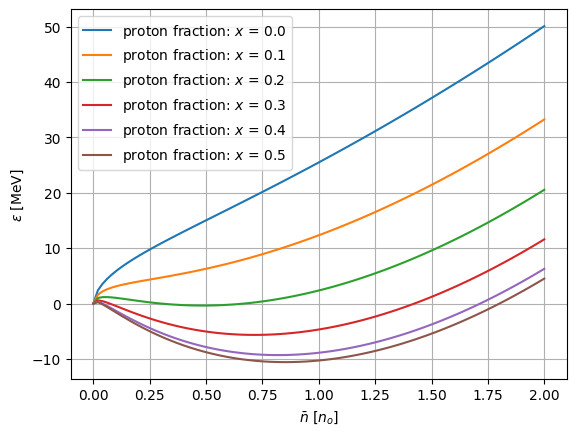

In [6]:
#Q2 Part 1.) 
import math
import numpy as np 
import matplotlib.pyplot as plt 

# Defining constants
T_o = 36.84 #unit: MeV 
n_o = 0.16 #unit: fm^-3 
alpha = 5.87 
gamma = 4.0/3.0 
eta = 3.81 
alpha_L = 1.4 
eta_L = 0.9 
m_p_csq = 938.272 #unit: MeV/c^2 proton mass
m_n_csq = 939.565 #unit: MeV/c^2 neutron mass
hbar_c = 197.326 #MeV-fm 

# Defining function total energy e(x,n_prime); energy density 
def e(x, n_bar): 
    '''
    This function defines a simple energy-per-particle model given in the question for neutron stars. It's a function 
    of proton fraction and combined neutron and proton density. 
    Parameters
    ----------
    x : float or numpy array
    Proton fraction. 
    n_bar : numpy array
    represents the combined neutron + proton densities that will be modeled for plotting

    Returns
    -------
    float or numpy array 
    just returns values of energy per particle given particular inputs of proton + neutron density and/or proton fraction.

    '''
    e_final = (((3.0/5.0)*(pow(x, 5.0/3.0) + pow((1-x), 5.0/3.0))*pow((2.8*n_bar), 2.0/3.0) 
    - ((2.0*alpha - 4.0*alpha_L)*x*(1.0 - x) + alpha_L)*n_bar 
    + ((2.0*eta - 4*eta_L)*x*(1.0 - x) + eta_L)*pow(n_bar, gamma)) * T_o)
    return e_final 

# Plotting of total energy function per n_bar per various x (proton fraction) 
x_frac = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5] #proton fraction possibilities
n_bar_plt = np.linspace(0.0, 2.0, 100) #horizontal grid points unit: n_o 
energy_vec = [e(x_frac[0], n_bar_plt), e(x_frac[1], n_bar_plt), e(x_frac[2], n_bar_plt), e(x_frac[3], n_bar_plt), e(x_frac[4], n_bar_plt), 
              e(x_frac[5], n_bar_plt)] #total energy per particle function in vectorized form
plt.plot(n_bar_plt, energy_vec[0], label = rf"proton fraction: $x$ = {x_frac[0]}") 
plt.plot(n_bar_plt, energy_vec[1], label = rf"proton fraction: $x$ = {x_frac[1]}") 
plt.plot(n_bar_plt, energy_vec[2], label = rf"proton fraction: $x$ = {x_frac[2]}") 
plt.plot(n_bar_plt, energy_vec[3], label = rf"proton fraction: $x$ = {x_frac[3]}") 
plt.plot(n_bar_plt, energy_vec[4], label = rf"proton fraction: $x$ = {x_frac[4]}") 
plt.plot(n_bar_plt, energy_vec[5], label = rf"proton fraction: $x$ = {x_frac[5]}") 
plt.legend(loc="best") 
plt.ylabel(r"$\epsilon$ [MeV]")
plt.xlabel(r"$\bar{n}$ [$n_o$]")
plt.grid(True)
plt.show()






**Q2 Part 1.) Physical Interpretations**

The observed energy density $\epsilon$ for around $\bar{n}$ = 1.0 $n_o$, and $x$ = $0.5$ corresponds to a minimum of that particluar 
energy density curve. 


**Q2 Part 2.) derivative analytical derivation**

- Starting with the total energy per particle model:
$\frac{\epsilon(\bar{n}, x)}{T_{o}}$ = $\frac{3}{5}[x^{5/3} + (1 - x)^{5/3}](2\bar{n})^{2/3} - [(2\alpha - 4\alpha_{L})x(1-x) + \alpha_{L}]\bar{n} 
+ [(2\eta - 4\eta_{L})x(1-x)  + \eta_{L}]\bar{\eta}^{\gamma}$

- taking the derivative of total energy per proton fraction ($x$): 
$\frac{1}{T_{o}}\frac{d}{dx}(\epsilon(\bar{n}, x))$ = 
$\frac{3}{5}\frac{d}{dx}([x^{5/3} + (1 - x)^{5/3}](2\bar{n})^{2/3})$
$-\frac{d}{dx}([(2\alpha - 4\alpha_{L})x(1-x) + \alpha_{L}]\bar{n})$
$+\frac{d}{dx}([(2\eta - 4\eta_{L})x(1-x) + \eta_{L}]\bar{n}^{\gamma})$

- differentiating each term: 
$\frac{3}{5}\frac{d}{dx}([x^{5/3} + (1 - x)^{5/3}](2\bar{n})^{2/3})$ = 
$\frac{3}{5}(2\bar{n})^{2/3}(\frac{5}{3}x^{2/3} + \frac{5}{3}(1-x)^{2/3}\cdot(-1))$
= $(2\bar{n})^{2/3}(x^{2/3} - (1-x)^{2/3})$

$-\bar{n}\frac{d}{dx}([(2\alpha - 4\alpha_{L})x(1-x) + \alpha_{L}])$ = 
$-\bar{n}((2\alpha - 4\alpha_{L})(1-x) - (2\alpha - 4\alpha_{L})x + \alpha_{L})$
= $\bar{n}(2\alpha - 4\alpha_{L})[2x - 1 - \frac{\alpha_{L}}{(2\alpha - 4\alpha_{L})}]$

$\bar{n}^{\gamma}\frac{d}{dx}([(2\eta - 4\eta_{L})x(1-x) + \eta_{L}])$ = 
$\bar{n}^{\gamma}((2\eta - 4\eta_{L})(1-x) - (2\eta - 4\eta_{L})x + \alpha_{L})$
= $\bar{n}(2\eta - 4\eta_{L})[-2x + 1 + \eta_{L}]$

- Final expression: 
$\frac{d\epsilon}{dx}$ = $T_{o}[(2\bar{n})^{2/3}(x^{2/3} - (1-x)^{2/3}) 
+ \bar{n}(2\alpha - 4\alpha_{L})[2x - 1 - \frac{\alpha_{L}}{(2\alpha - 4\alpha_{L})}]
+ \bar{n}(2\eta - 4\eta_{L})[-2x + 1 + \eta_{L}]]$





In [7]:
#Q2 Part 2.) Evaluating Derivative epsilon per x 
import math
import numpy as np 

# Derivative of energy per proton fraction (x) 
def d_esp_dx(x, n_bar): 
    '''
    This function is the first derivative of total energy per proton fraction (x) that is modeled 
    as a function of baryon density (proton + neutrons) and proton fraction. The goal of this function is to evaluate at 
    different cases of baryon density (n_bar) and proton fraction (x). 

    Parameters
    ----------
    x: float and/or numpy array(later)
    Proton fraction. 
    n_bar: float and/or numpy array(later)
    baryon density.

    Return
    ------
    float 
    Returns the value of the derivative for each particular case of baryon density and proton fraction. Unit: MeV.
    '''
    # Variable that defines the derivative desp/dx
    desp_dx = T_o*((pow((2.0*n_bar), 2.0/3.0)*(pow(x, 2.0/3.0) - pow((1.0 - x), 2.0/3.0)))
                   + (n_bar*(2.0*alpha - 4.0*alpha_L)*(2.0*x - 1.0 - (alpha_L/(2.0*alpha - 4.0- alpha_L))))
                   + (n_bar*(2.0*eta - 4.0*eta_L)*(-2.0*x + 1.0 + eta_L)))
    return desp_dx 

#Evaluating derivate per n_bar and x cases:
print(f"desp/dx(n = 1, x = 0) = {d_esp_dx(0.0, 1.0)} MeV")
print(f"\ndesp/dx(n = 2, x = 0.25) = {d_esp_dx(0.25, 2.0)} MeV")

desp/dx(n = 1, x = 0) = -53.24253159993439 MeV

desp/dx(n = 2, x = 0.25) = 48.78515826791607 MeV


**Outline plan for Part 3-4**

Starting with Eq. Condition: 
$\left[\frac{\partial \varepsilon(\bar{n}, x)}{\partial x}+ \mu_e(\bar{n}, x)\right]_{x = x_{\beta(\bar{n})}}- (m_n - m_p)c^2 = 0$.
This question(s) can find $x_\beta$ using a root-finding approach. Firstly, I'll define it by giving the equilibrium condition above 
by defining it as a function $f$($x_\beta$, $\bar{n}$), to see the shape and have an indication for initial guesses, I'm going to plot it for 
corresponding $\bar{n}$ cases: 0.5, 1.0, 2.0 $n_o$. Based on the shape of these cases, I'll use the scipy libraries for either doing 
Newton, Bisection, etc. 





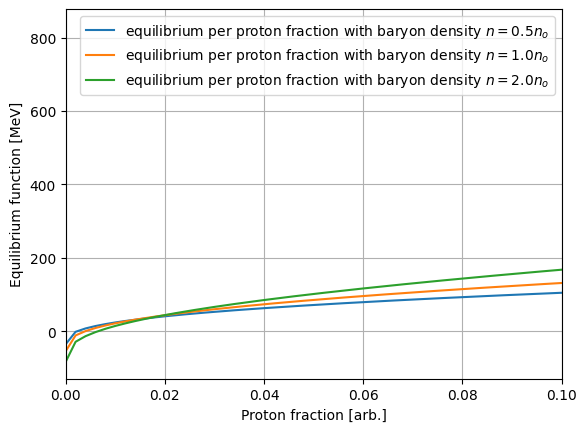

In [8]:
#Q2 Part 3.) Plotting 
import math
import numpy as np 
import matplotlib.pyplot as plt 

# defining equilibrium condition as a function 
def quib(x_bet, n_bar):
    '''
    This function presents the equilibrium condition above and defines it in a functional form, with applications to root finding (x_beta). 
    Parameters
    ----------
    x_bet: float or numpy array 
    Proton fraction. 
    n_bar: float or numpy array
    Baryon density (density of protons + neutrons)

    Return 
    ------
    float or numpy array 
    returns a value of he equilibrium condition for pairs of points of proton fraction (x_beta) and baryon density(n_bar). 

    '''
    
    m_p_csq = 938.272 #unit: MeV/c^2 proton mass
    m_n_csq = 939.565 #unit: MeV/c^2 neutron mass
    # variable that defines the condition 
    equi = (d_esp_dx(x_bet, n_bar) + hbar_c*pow((3.0*np.pi**2 * x_bet * n_o * n_bar), 1.0/3.0) - 
            (m_n_csq - m_p_csq))
    return equi 

#plotting for x_beta for cases: n_bar = [0.5, 1.0, 2.0]
x_bet_plt = np.linspace(0.0, 1.0, 500) #proton fraction gridpoints (x) at beta-equilibrium
plt.plot(x_bet_plt, quib(x_bet_plt, 0.5), label = rf"equilibrium per proton fraction with baryon density $n = 0.5 n_o$")
plt.plot(x_bet_plt, quib(x_bet_plt, 1.0), label = rf"equilibrium per proton fraction with baryon density $n = 1.0 n_o$")
plt.plot(x_bet_plt, quib(x_bet_plt, 2.0), label = rf"equilibrium per proton fraction with baryon density $n = 2.0 n_o$")
plt.legend(loc="best") 
plt.ylabel("Equilibrium function [MeV]")
plt.xlabel("Proton fraction [arb.]")
plt.xlim(0.0, 0.1)
plt.grid(True)
plt.show()








In [9]:
#Q2 Part 3.) Root finding for each x_beta case 

import math
import numpy as np 
from scipy.optimize import bisect 

# using bisection method to find each x: 
n_bar1 = [0.5, 1.0, 2.0] 
f1 = lambda x1: quib(x1, n_bar1[0])
f2 = lambda x2: quib(x2, n_bar1[1])
f3 = lambda x3: quib(x3, n_bar1[2])  # Create functions for each case of baryon density 

# n = 0.5 case: 
print(f"for case n_bar = {n_bar1[0]}, proton fraction (x_bet) = {bisect(f1, 1e-7, 0.1): .5f}")
# n = 1.0 case: 
print(f"for case n_bar = {n_bar1[1]}, proton fraction (x_bet) = {bisect(f2, 1e-7, 0.1): .5f}")
# n = 2.0 case: 
print(f"for case n_bar = {n_bar1[2]}, proton fraction (x_bet) = {bisect(f3, 1e-7, 0.1): .5f}")

print("\nBased on each of these values it safe to say that for all cases you have neutron richness at these densities.") 


for case n_bar = 0.5, proton fraction (x_bet) =  0.00228
for case n_bar = 1.0, proton fraction (x_bet) =  0.00393
for case n_bar = 2.0, proton fraction (x_bet) =  0.00651

Based on each of these values it safe to say that for all cases you have neutron richness at these densities.


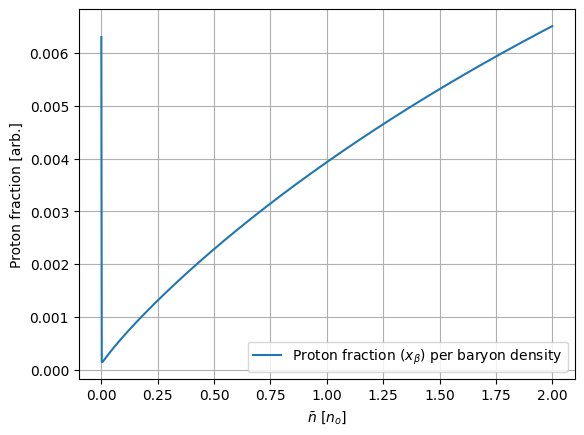

In [10]:
#Q2 Part 4.) 
import math
import numpy as np 
from scipy.optimize import bisect 
import matplotlib.pyplot as plt


# creating and storing the important arrays 
n_bar = np.linspace(1e-5, 2.0, 1000) 
func = [] #array that holds the functional args or equib. condition
x_beta = [] #array that holds x_beta values per bisection method
for i in range(len(n_bar)): 
    func.append(lambda x, i=i: quib(x, n_bar[i]))
    x_beta.append(bisect(func[i], 1e-7, 1.0))


#plotting x_beta 
plt.plot(n_bar, x_beta, label = r"Proton fraction ($x_{\beta}$) per baryon density") 
plt.legend(loc="best") 
plt.xlabel(r"$\bar{n}$ [$n_o$]")
plt.ylabel("Proton fraction [arb.]")
plt.grid(True)
plt.show()


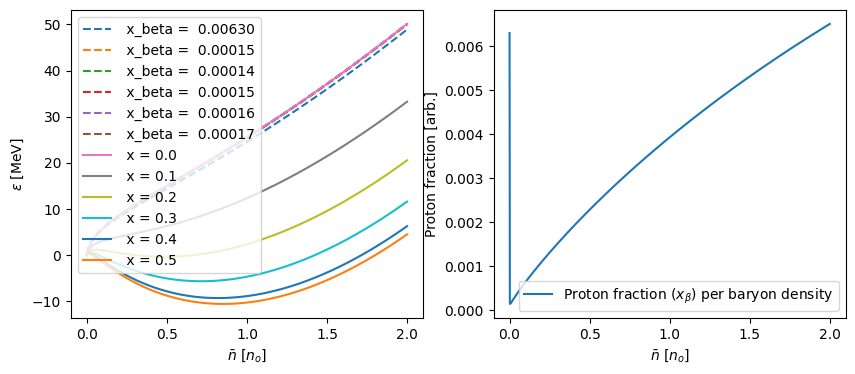

In [11]:
#Q2 Part 5.) 
import math
import numpy as np 
import matplotlib.pyplot as plt


# defining eps(x_beta, n_bar) 
n_bar = np.linspace(0.0, 2.0, 1000) 
eps_beta = [e(x_beta[0], n_bar), e(x_beta[1], n_bar), e(x_beta[2], n_bar), e(x_beta[3], n_bar), e(x_beta[4], n_bar), 
              e(x_beta[5], n_bar)] 


# redefining eps(x, n_bar) 
x_frac = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5] #proton fraction possibilities
eps_x = [e(x_frac[0], n_bar), e(x_frac[1], n_bar), e(x_frac[2], n_bar), e(x_frac[3], n_bar), e(x_frac[4], n_bar), 
              e(x_frac[5], n_bar)] #total energy density in vectorized form

# arrangements for subplot 
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
# Final setups for plots for energy per particle functional dependence of n_bar with x_beta and x proton fractions 
axes[0].plot(n_bar, eps_beta[0], "--", label = f" x_beta = {x_beta[0]: .5f}" )
axes[0].plot(n_bar, eps_beta[1], "--", label = f" x_beta = {x_beta[1]: .5f}")
axes[0].plot(n_bar, eps_beta[2], "--", label = f" x_beta = {x_beta[2]: .5f}")
axes[0].plot(n_bar, eps_beta[3], "--", label = f" x_beta = {x_beta[3]: .5f}")
axes[0].plot(n_bar, eps_beta[4],"--", label = f" x_beta = {x_beta[4]: .5f}")
axes[0].plot(n_bar, eps_beta[5],"--", label = f" x_beta = {x_beta[5]: .5f}")
axes[0].plot(n_bar, eps_x[0],label = f" x = {x_frac[0]}" )
axes[0].plot(n_bar, eps_x[1], label = f" x = {x_frac[1]}" )
axes[0].plot(n_bar, eps_x[2], label = f" x = {x_frac[2]}" )
axes[0].plot(n_bar, eps_x[3], label = f" x = {x_frac[3]}" )
axes[0].plot(n_bar, eps_x[4], label = f" x = {x_frac[4]}" )
axes[0].plot(n_bar, eps_x[5], label = f" x = {x_frac[5]}" )
axes[0].set_xlabel(r"$\bar{n}$ [$n_o$]")
axes[0].set_ylabel(r"$\epsilon$ [MeV]")
axes[0].legend(loc="best")
# Right panel plots of x_beta dependence on n_bar
axes[1].plot(n_bar, x_beta, label = r"Proton fraction ($x_{\beta}$) per baryon density")
axes[1].set_xlabel(r"$\bar{n}$ [$n_o$]")
axes[1].set_ylabel("Proton fraction [arb.]")
axes[1].legend(loc="best")
